In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [57]:

df = pd.read_csv("1 practice/students.csv")

Uploaded database of students (from Intro to ML)

In [15]:
df.head()

,stud.id,name,gender,age,height,weight,religion,nc.score,semester,major,minor,score1,score2,online.tutorial,graduated,salary
0,833917,"Gonzales, Christina",Female,19,160,64.8,Muslim,1.91,1st,Political Science,Social Sciences,NaN,NaN,0,0,NaN
1,898539,"Lozano, T'Hani",Female,19,172,73.0,Other,1.56,2nd,Social Sciences,Mathematics and Statistics,NaN,NaN,0,0,NaN
2,379678,"Williams, Hanh",Female,22,168,70.6,Protestant,1.24,3rd,Social Sciences,Mathematics and Statistics,45.0,46.0,0,0,NaN
3,807564,"Nem, Denzel",Male,19,183,79.7,Other,1.37,2nd,Environmental Sciences,Mathematics and Statistics,NaN,NaN,0,0,NaN
4,383291,"Powell, Heather",Female,21,175,71.4,Catholic,1.46,1st,Environmental Sciences,Mathematics and Statistics,NaN,NaN,0,0,NaN


Checked first five rows from the table

In [16]:
df.shape

(8239, 16)

Checked the size of the database

In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8239 entries, 0 to 8238
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   stud.id          8239 non-null   int64  
 1   name             8239 non-null   str    
 2   gender           8239 non-null   str    
 3   age              8239 non-null   int64  
 4   height           8239 non-null   int64  
 5   weight           8239 non-null   float64
 6   religion         8239 non-null   str    
 7   nc.score         8239 non-null   float64
 8   semester         8239 non-null   str    
 9   major            8239 non-null   str    
 10  minor            8239 non-null   str    
 11  score1           4892 non-null   float64
 12  score2           4892 non-null   float64
 13  online.tutorial  8239 non-null   int64  
 14  graduated        8239 non-null   int64  
 15  salary           1753 non-null   float64
dtypes: float64(5), int64(5), str(6)
memory usage: 1.5 MB


In [20]:
df.describe()

,stud.id,age,height,weight,nc.score,score1,score2,online.tutorial,graduated,salary
count,8239.000000,8239.000000,8239.000000,8239.000000,8239.000000,4892.000000,4892.000000,8239.000000,8239.000000,1753.000000
mean,548910.484525,22.541571,171.380750,72.998131,2.166481,68.164963,69.494685,0.386212,0.212769,42522.112364
std,253849.389811,6.065111,11.077529,8.635162,0.811548,14.051762,14.395251,0.486910,0.409290,10333.139906
min,110250.000000,18.000000,135.000000,51.400000,1.000000,30.000000,31.000000,0.000000,0.000000,11444.141650
25%,331222.500000,20.000000,163.000000,66.500000,1.460000,58.000000,59.000000,0.000000,0.000000,35206.541600
50%,545132.000000,21.000000,171.000000,71.800000,2.040000,70.000000,71.000000,0.000000,0.000000,41672.009750
75%,770807.500000,23.000000,180.000000,78.500000,2.780000,78.000000,80.000000,1.000000,0.000000,49372.540910
max,989901.000000,64.000000,206.000000,116.000000,4.000000,97.000000,98.000000,1.000000,1.000000,75596.793440


In [21]:
df.isnull().sum()

stud.id               0
name                  0
gender                0
age                   0
height                0
weight                0
religion              0
nc.score              0
semester              0
major                 0
minor                 0
score1             3347
score2             3347
online.tutorial       0
graduated             0
salary             6486
dtype: int64

Checked if there are null value in rows

In [23]:
df.groupby('graduated')['salary'].apply(lambda x: x.isnull().sum())

graduated
0    6486
1       0
Name: salary, dtype: int64

There are 6486 null values in 'salary' because there are 6486 ungraduated students, meaning that they are not paid money during university

In [24]:
df[df['score1'].isnull()]['semester'].value_counts()

semester
1st    1709
2nd    1638
Name: count, dtype: int64

In [25]:
df[df['score2'].isnull()]['semester'].value_counts()

semester
1st    1709
2nd    1638
Name: count, dtype: int64

In [31]:
df.groupby('semester')['score1'].agg(total = 'size', missing = lambda x: x.isnull().sum())

,total,missing
semester,,
1st,1709,1709
2nd,1638,1638
3rd,1641,0
4th,1368,0
5th,876,0
6th,704,0
>6th,303,0


3,347 missing values in score1 and score2 occur exclusively during the 1st and 2nd semesters. these courses are taken starting from the 3rd semester

In [32]:
df.columns

Index(['stud.id', 'name', 'gender', 'age', 'height', 'weight', 'religion',
       'nc.score', 'semester', 'major', 'minor', 'score1', 'score2',
       'online.tutorial', 'graduated', 'salary'],
      dtype='str')

Checked all columns names

In [33]:
df.columns = df.columns.str.replace('.', '_', regex=False)

Changed style to snake case

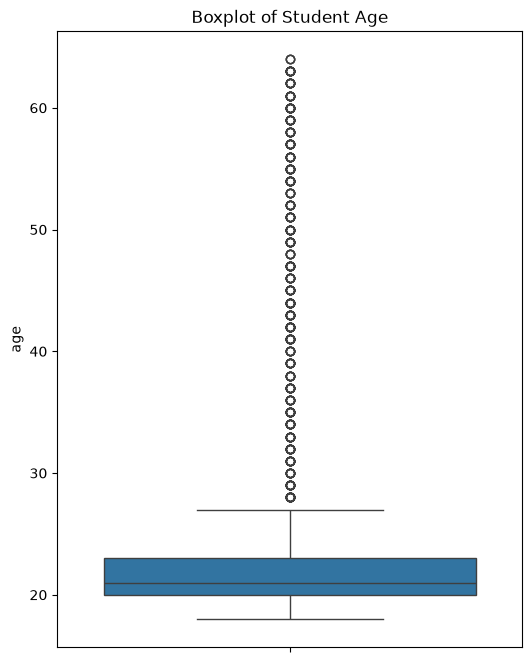

Lower Bound (Q1 - 1.5*IQR): 15.50
Upper Bound (Q3 + 1.5*IQR): 27.50
Total outliers detected in 'age': 429

First 5 outlier records:
    stud_id                 name  gender  age
21   499002  Culbertson, Deshawn    Male   37
23   807361   Johnson, Stephanie  Female   38
28   544433       Diawara, Erica  Female   54
60   373120    Livingston, Sarah  Female   44
64   401840    Nicholson, Willow  Female   32


In [38]:
plt.figure(figsize= (6,8))
sns.boxplot(y = df['age'])
plt.title('Boxplot of Student Age')
plt.show()

Q1 = df['age'].quantile(0.25)
Q3 = df['age'].quantile(0.75)
IQR = Q3- Q1
lower_bound = Q1 - 1.5*IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['age'] < lower_bound) | (df['age'] > upper_bound)]

print(f"Lower Bound (Q1 - 1.5*IQR): {lower_bound:.2f}")
print(f"Upper Bound (Q3 + 1.5*IQR): {upper_bound:.2f}")
print(f"Total outliers detected in 'age': {len(outliers)}")
print("\nFirst 5 outlier records:")
print(outliers[['stud_id', 'name', 'gender', 'age']].head())

Majority of students lies within IQR bounds, but there are still a lot of outliers up to 60+ years

In [42]:
unique_major = df['major'].unique()
unique_major

<ArrowStringArray>
[         'Political Science',            'Social Sciences',
     'Environmental Sciences',      'Economics and Finance',
 'Mathematics and Statistics',                    'Biology']
Length: 6, dtype: str

Printed unique values for column 'major'

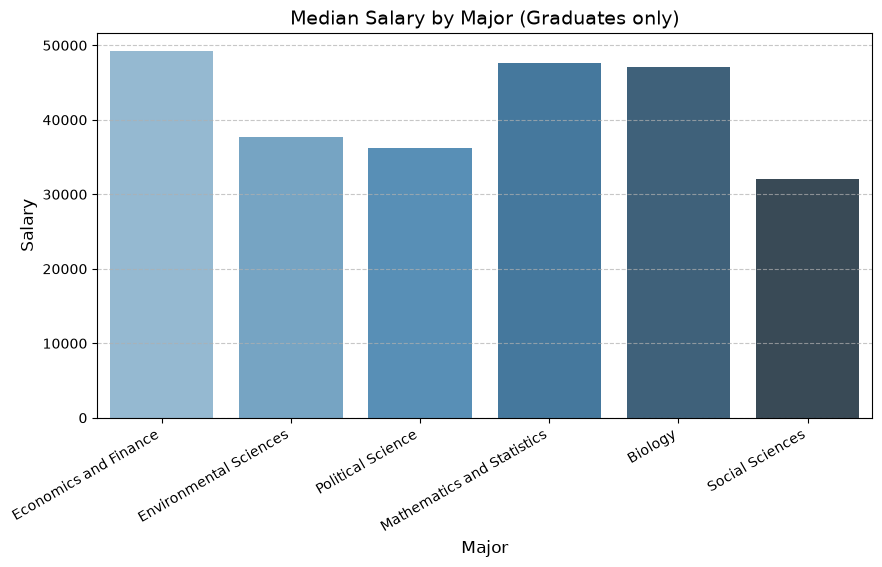

In [58]:
graduates_df = df[df['graduated']==1]
plt.figure(figsize=(10, 5))
sns.barplot(
    data=graduates_df,
    x = 'major',
    y = 'salary',
    hue = 'major',
    legend = False,
    estimator = 'median',
    errorbar = None,
    palette = 'Blues_d'
)
plt.title('Median Salary by Major (Graduates only)', fontsize = 14)
plt.xlabel('Major', fontsize = 12)
plt.ylabel('Salary', fontsize = 12)
plt.xticks(rotation = 30, ha = 'right')
plt.grid(axis = 'y', linestyle = '--', alpha = 0.7)
plt.show()

Barchart represent the difference of median between outcomes of students (graduates only) from different majors. Based on the visualization, Economics is the  highest payed outcome, whereas Social Science is the lowest.

In [18]:
counts_gender = df['gender'].value_counts()

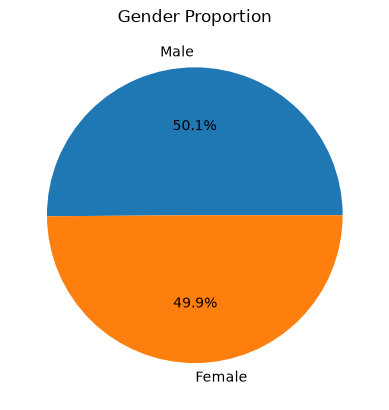

In [19]:
plt.pie(counts, labels = counts.index, autopct = '%1.1f%%')
plt.title('Gender Proportion')
plt.show()

Propotion of Gender

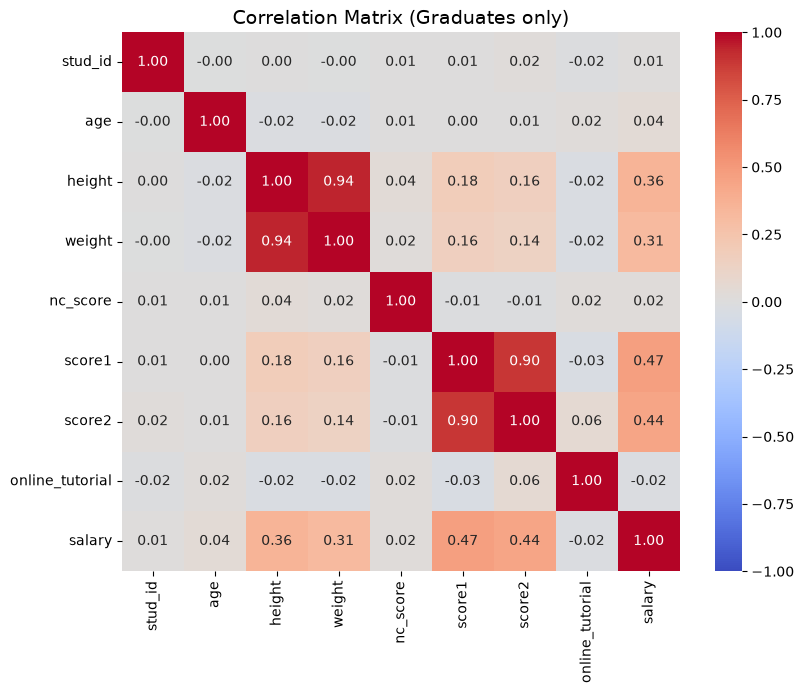

In [47]:
grad_numeric = df[df['graduated'] == 1].select_dtypes(include='number').drop(columns=['graduated'])
plt.figure(figsize=(9,7))
sns.heatmap(grad_numeric.corr(), annot = True, cmap = 'coolwarm', fmt = '.2f', vmin = -1, vmax = 1)
plt.title('Correlation Matrix (Graduates only)', fontsize = 14)
plt.show()

Correlation Matrix strong internal consistency and a moderate positive relationship with post-graduation earnings. In contrast, entrance scores (nc_score), age, and online tutorial participation show virtually no linear correlation with final salaries 

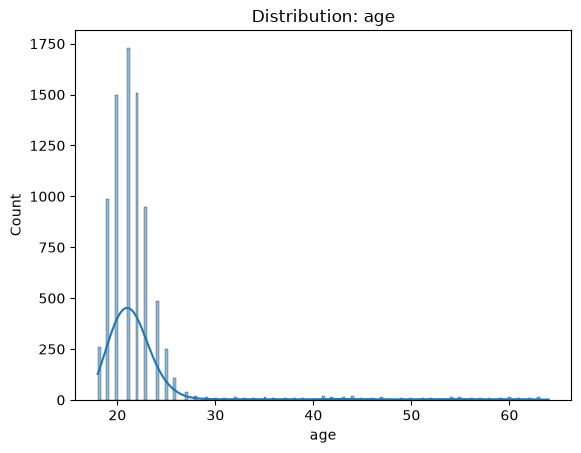

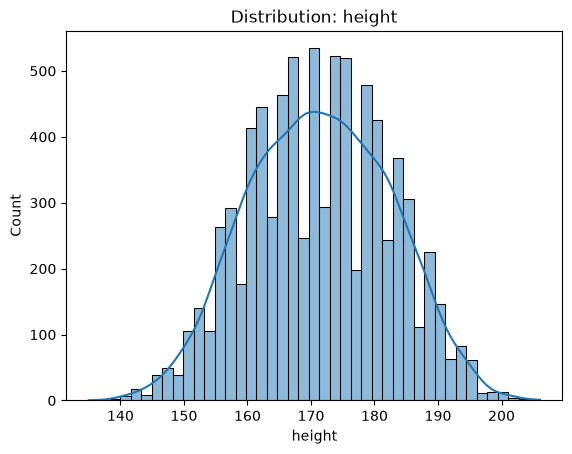

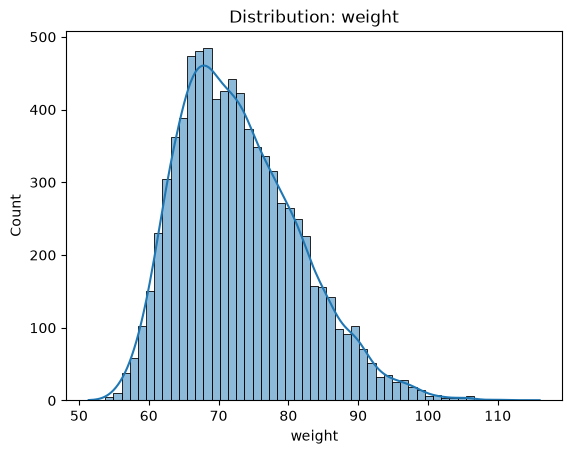

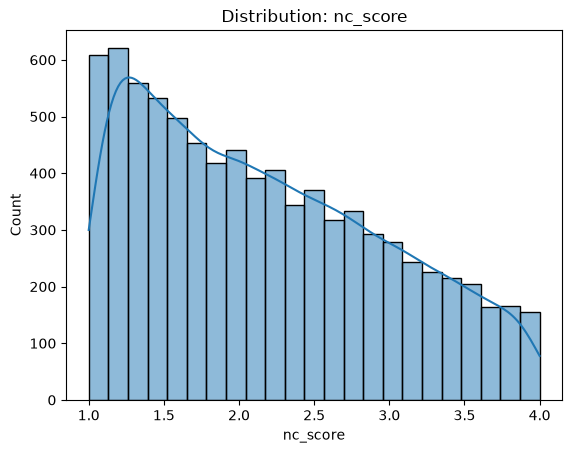

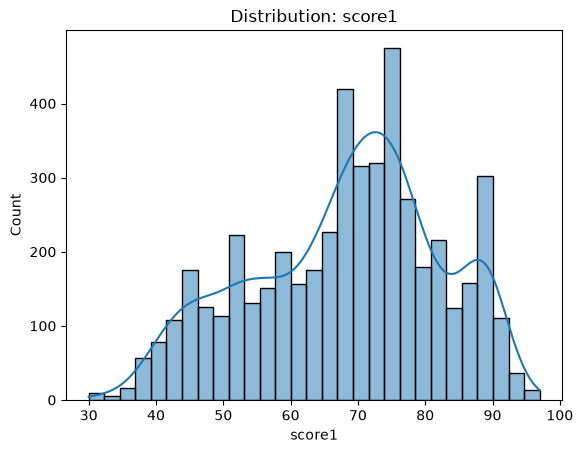

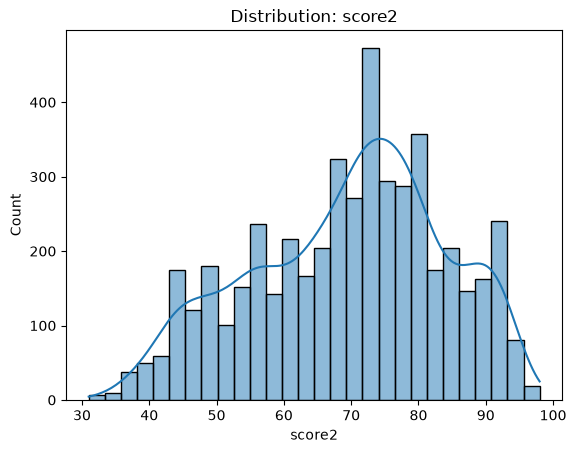

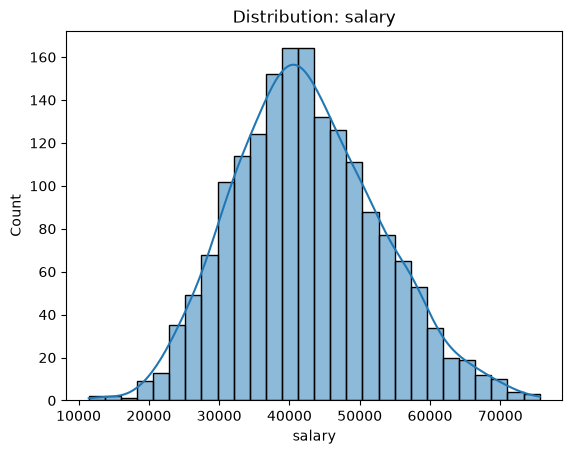

In [53]:
numeric_cols = ['age', 'height', 'weight', 'nc_score', 'score1', 'score2', 'salary']

for col in numeric_cols:
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution: {col}')
    plt.show()


Plotted histograms with KDE to show the distribution of each numeric variable (age, height, weight, nc.score, score1, score2, salary)

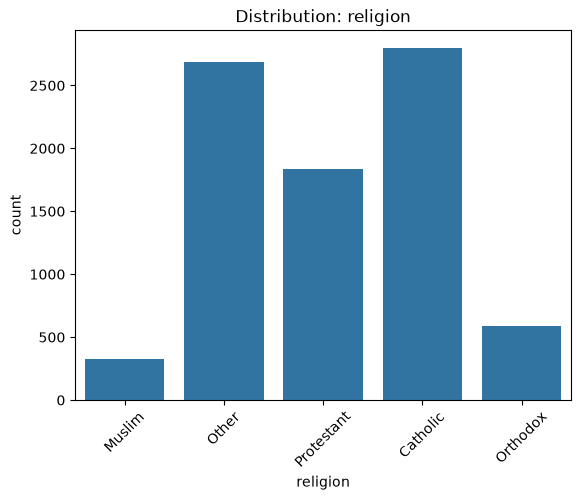

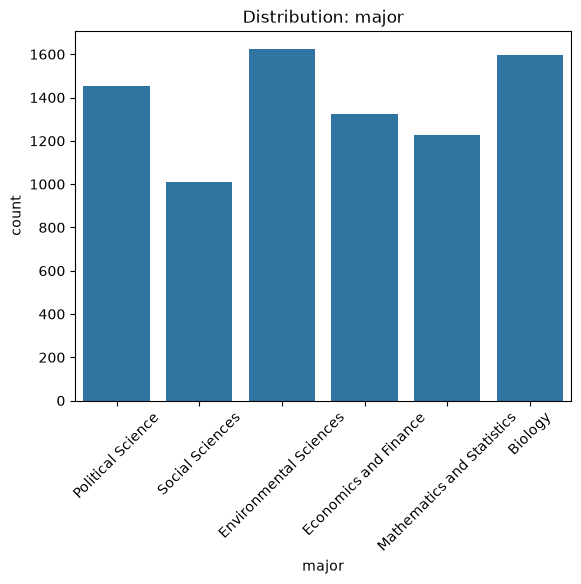

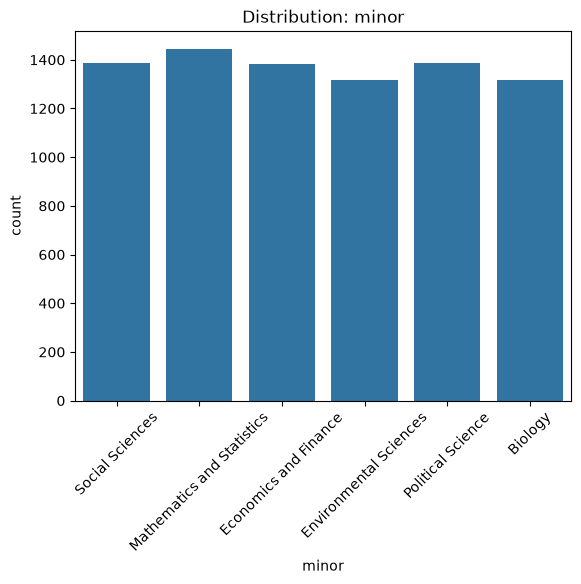

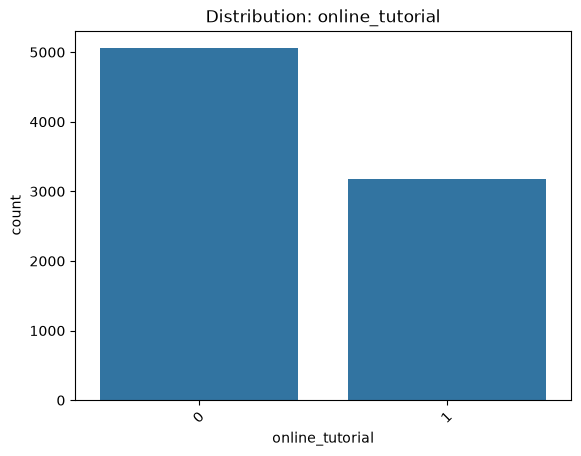

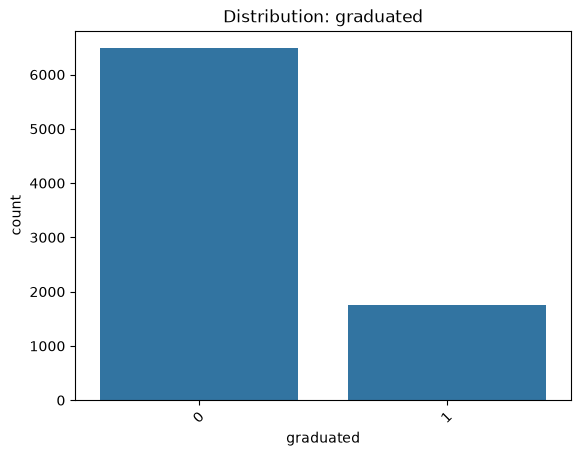

In [55]:
categorical_cols = ['religion', 'major', 'minor', 'online_tutorial', 'graduated']

for col in categorical_cols:
    sns.countplot(data=df, x=col)
    plt.title(f'Distribution: {col}')
    plt.xticks(rotation=45)  
    plt.show()

Bar charts were created for each categorical variable to clearly show the frequencyof each category

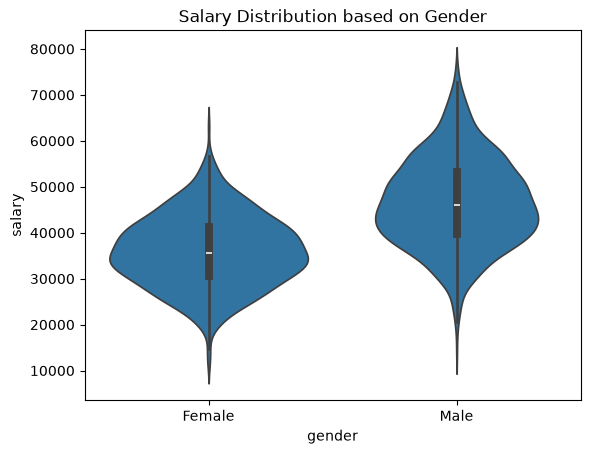

In [56]:
sns.violinplot(data=df, x='gender', y='salary')
plt.title('Salary Distribution based on Gender')
plt.show()

Based on the salary distribution, it can be seen that the median for women is around 36,000, whereas for men it is around 46,000. Moreover, men tend to have higher salaries overall.